# Phase 1: Tafel Polarization Curves, Faraday Corrosion Rate & Galvanic Driving Force Screening

This notebook demonstrates the complete Phase 1 deterministic physics workflow:
1. Retrieving electrochemical parameters $(E_{\text{corr}}, i_{\text{corr}}, \beta_a, \beta_c)$ from the harmonized database or manual input.
2. Generating activation-controlled **Polarization Curves** via the four-parameter base-10 Wagner-Traud equation (ADR-0001) and plotting annotated Tafel curves.
3. Converting **Corrosion Current Density ($i_{\text{corr}}$)** to **Initial Corrosion Rate ($\text{CR}_0$)** ($\text{nm/min}$ and $\text{mm/yr}$) and linear **Corrosion Depth** via Faraday's law with built-in **Dissolution Valence ($z$)** defaults and overrides.
4. Screening bimetallic pairs for **Galvanic Driving Force Risk** ($|\Delta E_{\text{corr}}|$) and identifying the **Active Metal** vs. **Noble Metal**.

In [1]:
from pathlib import Path
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from corrosion_simulator import (
    CORE_METALS,
    ExposureCondition,
    HarmonizedDatabase,
    PolarizationParameters,
    calculate_faraday_corrosion_rate,
    generate_polarization_curve,
    plot_tafel_curve,
    screen_galvanic_driving_force,
    screen_galvanic_pair_from_database,
    wagner_traud_anodic_current,
    wagner_traud_cathodic_current,
    wagner_traud_net_current,
)

db = HarmonizedDatabase.from_seed()
print(f'Loaded seed HarmonizedDatabase: {len(db.electrochemical_database)} records across {len(db.material_properties)} metals.')

Loaded seed HarmonizedDatabase: 33 records across 8 metals.


## 1. Database Lookup vs. Manual Parameter Input & Wagner-Traud Invariants

In [2]:
cu_lookup = db.lookup_exposure_condition(
    ExposureCondition(metal='Cu', pH=4.0, oxidizer_type='H2O2', oxidizer_concentration=1.0, temperature_C=25.0)
)
co_lookup = db.lookup_exposure_condition(
    ExposureCondition(metal='Co', pH=4.0, oxidizer_type='H2O2', oxidizer_concentration=1.0, temperature_C=25.0)
)
manual_cu = PolarizationParameters(
    Ecorr_V_SHE=0.250, icorr_uA_cm2=5.0, beta_a_mV_dec=65.0, beta_c_mV_dec=120.0, metal='Cu (Manual)'
)

for label, p in [('Cu (DB Lookup)', PolarizationParameters.from_lookup_result(cu_lookup)), ('Cu (Manual)', manual_cu)]:
    ia_eq = wagner_traud_anodic_current(p.Ecorr_V_SHE, p)
    ic_eq = wagner_traud_cathodic_current(p.Ecorr_V_SHE, p)
    inet_eq = wagner_traud_net_current(p.Ecorr_V_SHE, p)
    ia_plus_ba = wagner_traud_anodic_current(p.Ecorr_V_SHE + p.beta_a_V_dec, p)
    print(f'{label}: E_corr={p.Ecorr_V_SHE:+.3f} V, i_corr={p.icorr_uA_cm2:.2f} uA/cm2 | '
          f'i_a(E_corr)={ia_eq:.2f}, i_c(E_corr)={ic_eq:.2f}, i_net(E_corr)={inet_eq:.2e}, '
          f'i_a(E_corr+beta_a)/i_corr={ia_plus_ba / p.icorr_uA_cm2:.2f}x')

Cu (DB Lookup): E_corr=+0.285 V, i_corr=2.30 uA/cm2 | i_a(E_corr)=2.30, i_c(E_corr)=2.30, i_net(E_corr)=0.00e+00, i_a(E_corr+beta_a)/i_corr=10.00x
Cu (Manual): E_corr=+0.250 V, i_corr=5.00 uA/cm2 | i_a(E_corr)=5.00, i_c(E_corr)=5.00, i_net(E_corr)=0.00e+00, i_a(E_corr+beta_a)/i_corr=10.00x


## 2. Annotated Tafel Polarization Curves ($E$ vs. $\log_{10}|i|$)

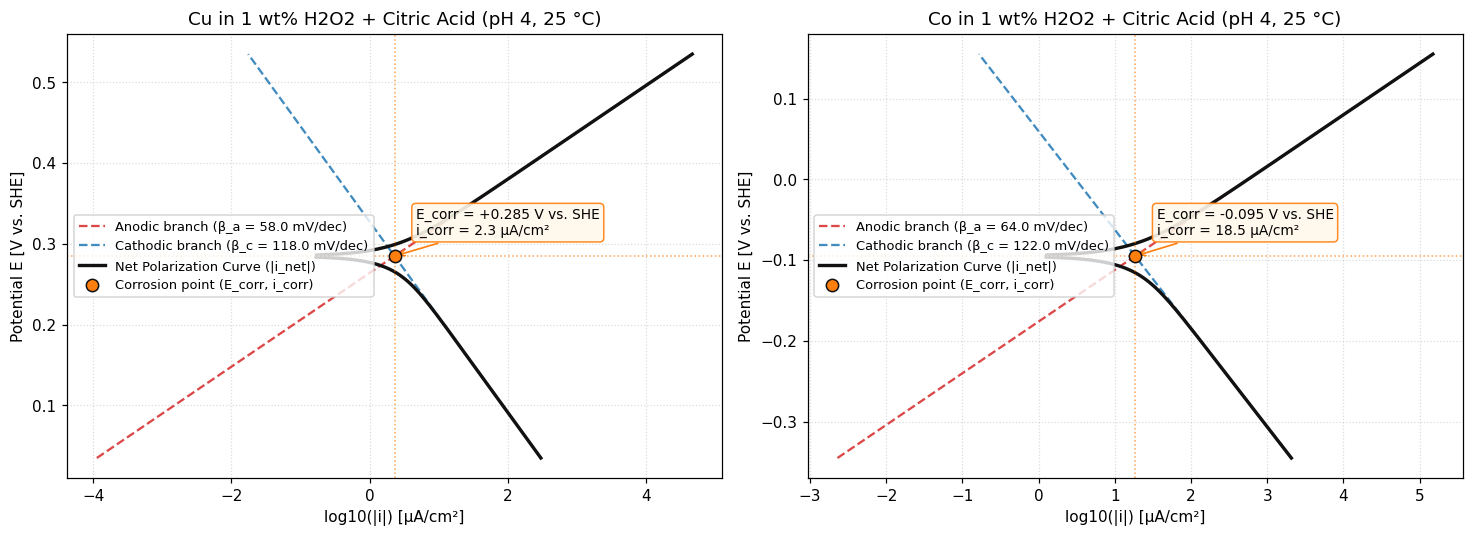

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.0))
plot_tafel_curve(cu_lookup, ax=axes[0], title='Cu in 1 wt% H2O2 + Citric Acid (pH 4, 25 °C)')
plot_tafel_curve(co_lookup, ax=axes[1], title='Co in 1 wt% H2O2 + Citric Acid (pH 4, 25 °C)')
plt.tight_layout()
plt.show()

## 3. Faraday's Law: Initial Corrosion Rate ($\text{CR}_0$) & Linear Corrosion Depth

In [4]:
rows = []
for metal in CORE_METALS:
    res_lookup = db.lookup_exposure_condition(
        ExposureCondition(metal=metal, pH=4.0, oxidizer_type='H2O2', oxidizer_concentration=1.0, temperature_C=25.0)
    )
    faraday = calculate_faraday_corrosion_rate(
        metal, res_lookup.icorr_uA_cm2, immersion_time_s=60.0, material_properties=db.material_properties
    )
    rows.append({
        'Metal': metal,
        'E_corr (V vs. SHE)': res_lookup.Ecorr_V_SHE,
        'i_corr (uA/cm2)': res_lookup.icorr_uA_cm2,
        'Valence (z)': faraday.dissolution_valence,
        'CR_0 (nm/min)': faraday.corrosion_rate_nm_min,
        'CR_0 (mm/yr)': faraday.corrosion_rate_mm_yr,
        'Depth @ 60 s (nm)': faraday.corrosion_depth_nm,
    })

faraday_df = pd.DataFrame(rows).sort_values('CR_0 (nm/min)', ascending=False)
print(faraday_df.to_string(index=False))

cu_z1 = calculate_faraday_corrosion_rate('Cu', cu_lookup.icorr_uA_cm2, valence=1, immersion_time_s=60.0)
print(f'\nValence override check — Cu (z=1) at {cu_lookup.icorr_uA_cm2:.2f} uA/cm2: '
      f'CR_0 = {cu_z1.corrosion_rate_nm_min:.5f} nm/min, depth @ 60 s = {cu_z1.corrosion_depth_nm:.5f} nm')

Metal  E_corr (V vs. SHE)  i_corr (uA/cm2)  Valence (z)  CR_0 (nm/min)  CR_0 (mm/yr)  Depth @ 60 s (nm)
   Co              -0.095            18.50            2       0.380871      0.200186           0.380871
   Al              -0.580             4.20            3       0.086995      0.045725           0.086995
   Mo               0.110             8.40            6       0.081259      0.042710           0.081259
    W               0.140             6.80            6       0.067306      0.035376           0.067306
   Cu               0.285             2.30            2       0.050722      0.026659           0.050722
   Ti              -0.150             0.65            4       0.010726      0.005637           0.010726
   Ru               0.520             0.12            4       0.001524      0.000801           0.001524
   Ta              -0.040             0.09            5       0.001214      0.000638           0.001214

Valence override check — Cu (z=1) at 2.30 uA/cm2: CR_0 = 0.1014

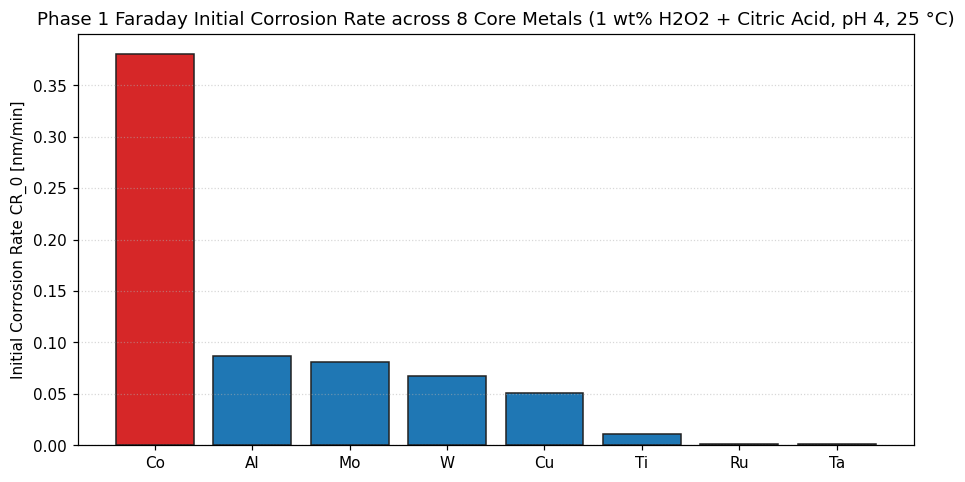

In [5]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
colors = ['#d62728' if v > 0.2 else '#1f77b4' for v in faraday_df['CR_0 (nm/min)']]
ax.bar(faraday_df['Metal'], faraday_df['CR_0 (nm/min)'], color=colors, edgecolor='#222222')
ax.set_ylabel('Initial Corrosion Rate CR_0 [nm/min]')
ax.set_title('Phase 1 Faraday Initial Corrosion Rate across 8 Core Metals (1 wt% H2O2 + Citric Acid, pH 4, 25 °C)')
ax.grid(axis='y', linestyle=':', alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Bimetallic Galvanic Driving Force Risk Screening ($|\Delta E_{\text{corr}}|$)

In [6]:
pair_rows = []
delta_matrix = pd.DataFrame(0.0, index=list(CORE_METALS), columns=list(CORE_METALS))
for m1, m2 in itertools.combinations(CORE_METALS, 2):
    scr = screen_galvanic_pair_from_database(
        db, m1, m2, pH=4.0, oxidizer_type='H2O2', oxidizer_concentration=1.0, temperature_C=25.0
    )
    delta_matrix.loc[m1, m2] = scr.delta_Ecorr_V
    delta_matrix.loc[m2, m1] = scr.delta_Ecorr_V
    pair_rows.append({
        'Active Metal': scr.active_metal,
        'Noble Metal': scr.noble_metal,
        '|Delta E_corr| (V)': scr.delta_Ecorr_V,
        'Galvanic Driving Force Risk': scr.risk_tier,
    })

pairs_df = pd.DataFrame(pair_rows).sort_values('|Delta E_corr| (V)', ascending=False)
print('Top 10 Highest Galvanic Driving Force Pairs:')
print(pairs_df.head(10).to_string(index=False))

Top 10 Highest Galvanic Driving Force Pairs:
Active Metal Noble Metal  |Delta E_corr| (V) Galvanic Driving Force Risk
          Al          Ru               1.100                        High
          Al          Cu               0.865                        High
          Al           W               0.720                        High
          Al          Mo               0.690                        High
          Ti          Ru               0.670                        High
          Co          Ru               0.615                        High
          Ta          Ru               0.560                        High
          Al          Ta               0.540                        High
          Al          Co               0.485                        High
          Ti          Cu               0.435                        High


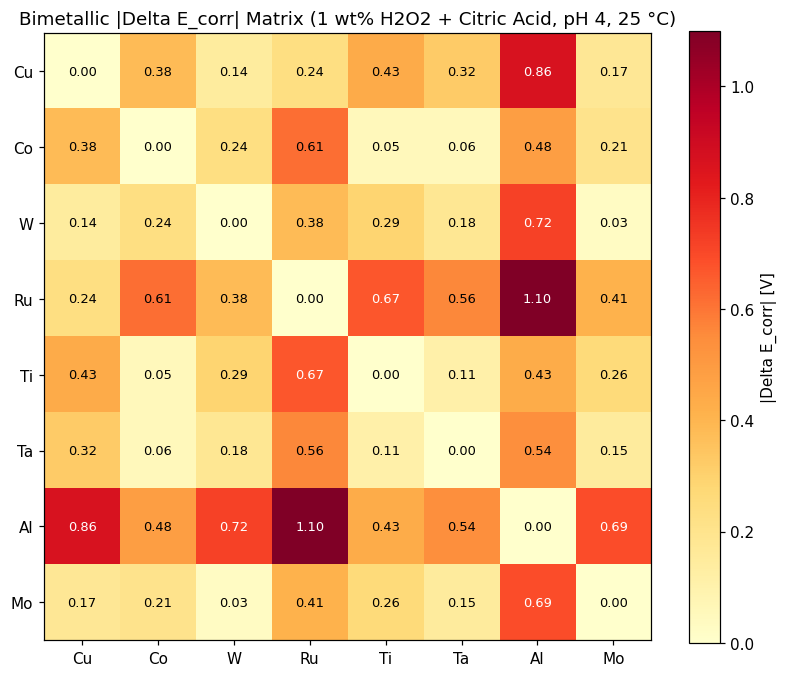

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(delta_matrix.values, cmap='YlOrRd', vmin=0.0, vmax=max(0.6, float(delta_matrix.values.max())))
ax.set_xticks(range(len(CORE_METALS)))
ax.set_yticks(range(len(CORE_METALS)))
ax.set_xticklabels(CORE_METALS)
ax.set_yticklabels(CORE_METALS)
for i in range(len(CORE_METALS)):
    for j in range(len(CORE_METALS)):
        val = delta_matrix.values[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center', fontsize=8.5, color='black' if val < 0.65 else 'white')
cbar = fig.colorbar(im, ax=ax, label='|Delta E_corr| [V]')
ax.set_title('Bimetallic |Delta E_corr| Matrix (1 wt% H2O2 + Citric Acid, pH 4, 25 °C)')
plt.tight_layout()
plt.show()